# Figure 3a, 3b, 3e: Experiment 1 (object arrays)

Zhang et al. (2018), *Finding any Waldo*, Nat. Commun. 9:3730. IVSN in the paper's configuration
(search 224x224 -> `features[:30]` 14x14x512; target 28x28 -> `features[:31]` 1x1x512;
MaxPool `ceil_mode=True`), scored by ranking the six array slots. No forced central fixation.

In [1]:
import os
os.chdir("/Users/natalynpong/fyp/ivsn-pytorch/codes")

import glob
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch
from PIL import Image
from scipy.io import loadmat
import torch
import torch.nn.functional as F
from torchvision import models, transforms

ARR = "dataset/datasets/array/"
OUT = "../results/Array/"
os.makedirs(OUT, exist_ok=True)

IMG_W, IMG_H = 676, 756
# slot boxes (x0, y0, x1, y1) and centres in the 676x756 array image; slot k = arraycate index k
BOXES   = {1: (0, 450, 155, 605), 2: (0, 150, 155, 305), 3: (260, 0, 415, 155),
           4: (520, 150, 675, 305), 5: (520, 450, 675, 605), 6: (260, 600, 415, 755)}
CENTRES = {1: (78, 528), 2: (78, 228), 3: (338, 78), 4: (598, 228), 5: (598, 528), 6: (338, 678)}

MyData = loadmat(ARR + "psy/array.mat", squeeze_me=True, struct_as_record=False)["MyData"]
N_ARRAYS = 300
target_slot = np.array([int(np.where(MyData[n].arraycate == MyData[n].targetcate)[0][0]) + 1
                        for n in range(N_ARRAYS)])          # 1..6, index n = array_{n+1}
print("arrays:", N_ARRAYS, "| target slot counts:", np.bincount(target_slot, minlength=7)[1:])

arrays: 300 | target slot counts: [50 53 47 50 46 54]


## Model

In [2]:
torch.set_grad_enabled(False)
vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).eval()
for m in vgg.features:
    if isinstance(m, torch.nn.MaxPool2d):
        m.ceil_mode = True                       # MatConvNet rounding; must precede everything else
for p in vgg.parameters():
    p.requires_grad_(False)

search_net = vgg.features[:30]                   # up to relu5_3 (paper layer 30)
target_net = vgg.features[:31]                   # up to pool5   (paper layer 31)

normalize = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
def prep(path, size):
    img = Image.open(path).convert("L").convert("RGB").resize((size, size), Image.BILINEAR)
    return normalize(transforms.functional.to_tensor(img)).unsqueeze(0)

def attention(n):
    """Upsampled IVSN attention map (756x676) for array_{n+1}."""
    s = search_net(prep(f"{ARR}stimuli/array_{n+1}.jpg", 224))
    t = target_net(prep(f"{ARR}target/target_{n+1}.jpg", 28))
    conv = torch.nn.Conv2d(512, 1, kernel_size=1, bias=False)
    conv.weight = torch.nn.Parameter(t)          # (1, 512, 1, 1)
    a = conv(s)                                  # (1, 1, 14, 14)
    return F.interpolate(a, size=(IMG_H, IMG_W), mode="bilinear", align_corners=False)[0, 0].numpy(), s.shape, t.shape, a.shape

_, s_shape, t_shape, a_shape = attention(0)
assert tuple(s_shape) == (1, 512, 14, 14), f"search features {tuple(s_shape)}, expected (1, 512, 14, 14)"
assert tuple(t_shape) == (1, 512, 1, 1),   f"target features {tuple(t_shape)}, expected (1, 512, 1, 1)"
assert tuple(a_shape) == (1, 1, 14, 14),   f"attention map {tuple(a_shape)}, expected (1, 1, 14, 14)"
print("shapes OK:", tuple(s_shape), tuple(t_shape), tuple(a_shape))

shapes OK: (1, 512, 14, 14) (1, 512, 1, 1) (1, 1, 14, 14)


## IVSN search: rank the six slots by peak attention

In [3]:
ivsn_rank  = np.zeros(N_ARRAYS, int)     # 1-based rank of the target slot
ivsn_order = np.zeros((N_ARRAYS, 6), int) # slots in descending peak-attention order
for n in range(N_ARRAYS):
    amap = attention(n)[0]
    peak = {k: amap[y0:y1 + 1, x0:x1 + 1].max() for k, (x0, y0, x1, y1) in BOXES.items()}
    order = sorted(peak, key=peak.get, reverse=True)
    ivsn_order[n] = order
    ivsn_rank[n] = order.index(target_slot[n]) + 1

ivsn_accu = np.array([(ivsn_rank <= k).mean() for k in range(1, 7)])
print("IVSN rank counts (1..6):", np.bincount(ivsn_rank, minlength=7)[1:])
print("IVSN cumulative:", np.round(ivsn_accu, 4))
print(f"IVSN mean fixations: {ivsn_rank.mean():.2f} +/- {ivsn_rank.std():.2f} (SD over arrays)")

IVSN rank counts (1..6): [89 64 49 42 29 27]
IVSN cumulative: [0.2967 0.51   0.6733 0.8133 0.91   1.    ]
IVSN mean fixations: 2.80 +/- 1.64 (SD over arrays)


## Humans: `cumsum(nanmean(scoremat))` per subject (MMAnalyzeFixResults.m line 120)

In [4]:
subj_files = sorted(f for f in glob.glob(ARR + "psy/ProcessScanpath_array/*.mat")
                    if "_oracle" not in f and "_saccade" not in f and "subj" in os.path.basename(f))
curves, mean_fix = [], []
for f in subj_files:
    sm = loadmat(f)["scoremat"].astype(float)          # 600 x 6, rows in image order
    curves.append(np.cumsum(np.nanmean(sm, axis=0)))
    found = np.nansum(sm, axis=1) == 1
    mean_fix.append((sm[found].argmax(axis=1) + 1).mean())
curves = np.array(curves)
human_accu, human_sd = curves.mean(axis=0), curves.std(axis=0, ddof=1)
human_sem = human_sd / np.sqrt(len(curves))
print("subjects:", len(subj_files), [os.path.basename(f)[:-4] for f in subj_files])
print("human cumulative:", np.round(human_accu, 4))
print("  SD across subj :", np.round(human_sd, 4))
print("  SEM            :", np.round(human_sem, 4))
print(f"human mean fixations (found trials): {np.mean(mean_fix):.2f} +/- {np.std(mean_fix, ddof=1):.2f} (SD over subjects)")

chance = np.arange(1, 7) / 6

subjects: 15 ['subj02-el', 'subj03-yu', 'subj05-je', 'subj07-pr', 'subj08-bo', 'subj09-az', 'subj10-oc', 'subj11-lu', 'subj12-al', 'subj13-ni', 'subj14-ji', 'subj15-ma', 'subj17-ga', 'subj18-an', 'subj19-ni']
human cumulative: [0.2617 0.5204 0.6889 0.8061 0.8873 0.9334]
  SD across subj : [0.0383 0.0535 0.0449 0.0363 0.0354 0.0383]
  SEM            : [0.0099 0.0138 0.0116 0.0094 0.0092 0.0099]
human mean fixations (found trials): 2.61 +/- 0.20 (SD over subjects)


## Figure 3a: example trial

example: array_5  target 'kite'  slot 6  IVSN order [2, 4, 6, 3, 1, 5]  rank 3


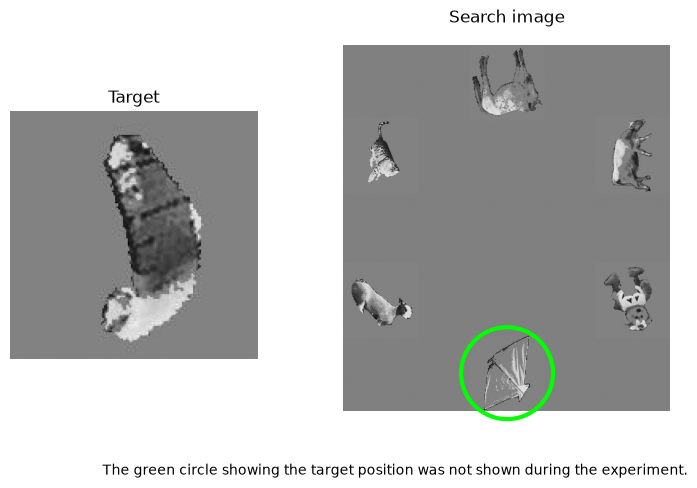

In [5]:
# example: first array where IVSN finds the target on its 3rd fixation, so the
# three-fixation scanpath in 3b ends on the target
EX = int(np.where(ivsn_rank == 3)[0][0])
print(f"example: array_{EX+1}  target '{MyData[EX].targetname}'  slot {target_slot[EX]}  "
      f"IVSN order {ivsn_order[EX].tolist()}  rank {ivsn_rank[EX]}")
def pad_axes(a, m=30, bottom=None):   # let slot circles extend past the image border
    a.set_xlim(-m, IMG_W - 1 + m); a.set_ylim(IMG_H - 1 + (m if bottom is None else bottom), -m)

arr_img = np.asarray(Image.open(f"{ARR}stimuli/array_{EX+1}.jpg").convert("L"))
tgt_img = np.asarray(Image.open(f"{ARR}target/target_{EX+1}.jpg").convert("L"))

fig, ax = plt.subplots(1, 2, figsize=(8, 4.6), gridspec_kw={"width_ratios": [1, 2.2]})
ax[0].imshow(tgt_img, cmap="gray", vmin=0, vmax=255); ax[0].set_title("Target")
ax[1].imshow(arr_img, cmap="gray", vmin=0, vmax=255); ax[1].set_title("Search image")
cx, cy = CENTRES[target_slot[EX]]
ax[1].add_patch(Circle((cx, cy), 95, fill=False, ec="lime", lw=3))
pad_axes(ax[1], bottom=60)
for a in ax: a.axis("off")
plt.tight_layout()
fig.text(0.5, -0.02, "The green circle showing the target position was not shown during the experiment.",
         ha="center", va="top", fontsize=10)
plt.savefig(OUT + "fig3a_example.png", dpi=200, bbox_inches="tight"); plt.show()

## Figure 3b: attention map and IVSN scanpath

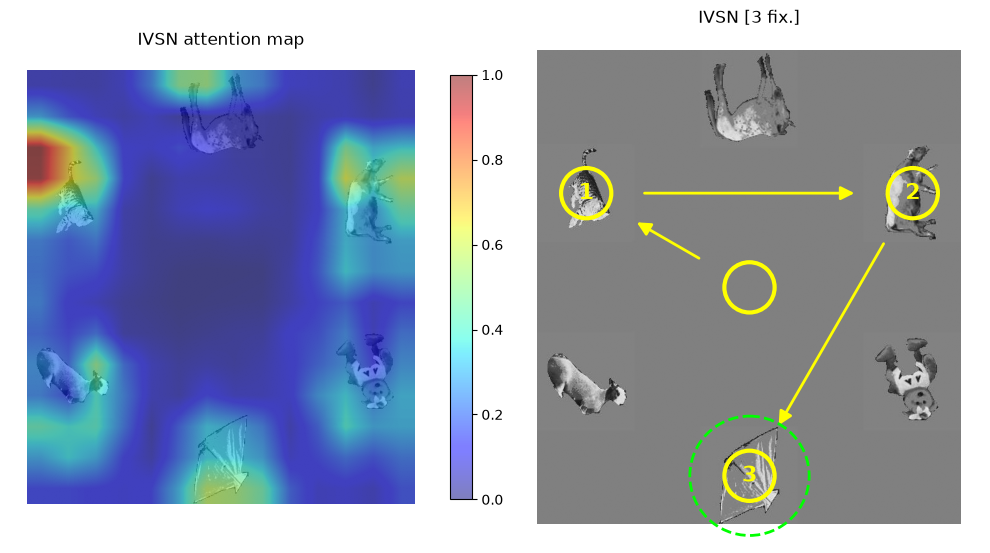

In [6]:
amap = attention(EX)[0]
amap01 = (amap - amap.min()) / (amap.max() - amap.min())

fig, ax = plt.subplots(1, 2, figsize=(10, 5.6))
ax[0].imshow(arr_img, cmap="gray", vmin=0, vmax=255)
im = ax[0].imshow(amap01, cmap="jet", alpha=0.5, vmin=0, vmax=1)
fig.colorbar(im, ax=ax[0], fraction=0.046, pad=0.04)
ax[0].set_title("IVSN attention map")

ax[1].imshow(arr_img, cmap="gray", vmin=0, vmax=255)
path = [CENTRES[k] for k in ivsn_order[EX][:3]]
start = (IMG_W // 2, IMG_H // 2)                 # central start, not counted as a fixation
ax[1].add_patch(Circle(start, 40, fill=False, ec="yellow", lw=3))
for i, (x, y) in enumerate(path):
    ax[1].add_patch(Circle((x, y), 40, fill=False, ec="yellow", lw=3))
    ax[1].text(x, y, str(i + 1), color="yellow", fontsize=16, ha="center", va="center", weight="bold")
for (x0, y0), (x1, y1) in zip([start] + path[:-1], path):
    ax[1].add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=20,
                                    color="yellow", lw=2, shrinkA=42, shrinkB=42))
tx, ty = CENTRES[target_slot[EX]]
ax[1].add_patch(Circle((tx, ty), 95, fill=False, ec="lime", lw=2, ls="--"))
ax[1].set_title(f"IVSN [{ivsn_rank[EX]} fix.]")
pad_axes(ax[0]); pad_axes(ax[1])
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(OUT + "fig3b_attention.png", dpi=200, bbox_inches="tight"); plt.show()

## Figure 3e: cumulative performance

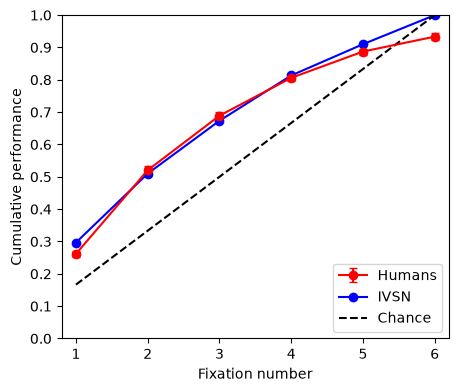

In [7]:
x = np.arange(1, 7)
plt.figure(figsize=(5, 4.2))
h = plt.errorbar(x, human_accu, yerr=human_sem, color="red", marker="o", capsize=3, label="Humans")
m, = plt.plot(x, ivsn_accu, color="blue", marker="o", label="IVSN")
c, = plt.plot(x, chance, "k--", label="Chance")
plt.xlabel("Fixation number"); plt.ylabel("Cumulative performance")
plt.xticks(x); plt.yticks(np.round(np.arange(0, 1.01, 0.1), 1))
plt.xlim(0.8, 6.2); plt.ylim(0, 1)
plt.legend([h, m, c], ["Humans", "IVSN", "Chance"], loc="lower right")
plt.savefig(OUT + "fig3e_cumulative.png", dpi=200, bbox_inches="tight"); plt.show()

## Comparison with the published Figure 3e

In [8]:
paper_h = np.array([0.26, 0.52, 0.69, 0.80, 0.89, 0.93])
paper_m = np.array([0.32, 0.52, 0.67, 0.80, 0.89, 1.00])
print("fix   human   paper   diff  |  IVSN    paper   diff  | chance")
for k in range(6):
    print(f" {k+1}   {human_accu[k]:.3f}   {paper_h[k]:.2f}  {human_accu[k]-paper_h[k]:+.3f} |  "
          f"{ivsn_accu[k]:.3f}   {paper_m[k]:.2f}  {ivsn_accu[k]-paper_m[k]:+.3f} | {chance[k]:.3f}")
print(f"max |diff|: humans {np.abs(human_accu - paper_h).max():.3f}, IVSN {np.abs(ivsn_accu - paper_m).max():.3f}")
print(f"mean fixations: humans {np.mean(mean_fix):.2f} +/- {np.std(mean_fix, ddof=1):.2f} (paper 2.60 +/- 0.22), "
      f"IVSN {ivsn_rank.mean():.2f} +/- {ivsn_rank.std():.2f} (paper 2.80 +/- 1.71)")

fix   human   paper   diff  |  IVSN    paper   diff  | chance
 1   0.262   0.26  +0.002 |  0.297   0.32  -0.023 | 0.167
 2   0.520   0.52  +0.000 |  0.510   0.52  -0.010 | 0.333
 3   0.689   0.69  -0.001 |  0.673   0.67  +0.003 | 0.500
 4   0.806   0.80  +0.006 |  0.813   0.80  +0.013 | 0.667
 5   0.887   0.89  -0.003 |  0.910   0.89  +0.020 | 0.833
 6   0.933   0.93  +0.003 |  1.000   1.00  +0.000 | 1.000
max |diff|: humans 0.006, IVSN 0.023
mean fixations: humans 2.61 +/- 0.20 (paper 2.60 +/- 0.22), IVSN 2.80 +/- 1.64 (paper 2.80 +/- 1.71)
